In [40]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


In [ ]:
c1 = np.random.normal(loc=[2, 3, 8], scale=[1, 1.5, 1], size=(100, 3))
c2 = np.random.normal(loc=[8, 3, 2], scale=[1, 1, 1.5], size=(100, 3))
c3 = np.random.normal(loc=[5, 8, 5], scale=[1.5, 1, 1], size=(100, 3))
X = np.vstack((c1, c2, c3)) 
y = [0]*100 + [1]*100 + [2]*100
Y = np.eye(3)[y]
print(X.shape,Y.shape)
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

(300, 3) (300, 3)
[[ 5.62933812  7.85249466  5.17448366]
 [ 5.7537802   7.99747815  2.57160439]
 [ 8.87461299  2.75475274 -0.43193569]
 [ 1.10283294  3.44145392  7.83497909]
 [ 5.32115483  8.33532012  4.84464047]
 [ 8.77487253  8.8808727   5.32064604]
 [ 6.7119344   2.05120869  3.5208265 ]
 [ 8.13568006  2.24799034  3.76486652]
 [ 3.14547479  1.36577142  8.54667598]
 [ 8.82873307  2.012913    2.30731832]
 [ 6.34942237  9.28822206  5.31111404]
 [ 2.40522651  1.68781196  8.84067269]
 [ 7.80658405  7.64436021  5.08464289]
 [ 3.17390127  1.8557026   7.78700913]
 [ 8.95902907  2.47227515 -0.27144084]
 [ 5.95965681  7.65560276  5.31720631]
 [ 5.47688661  9.38315161  4.88417234]
 [ 5.77045423  7.06537249  4.99831298]
 [ 7.6376086   3.16181369  2.96581115]
 [ 8.94534134  0.88229864  0.64144457]
 [ 2.37228552  2.79732844  6.19806371]
 [ 7.4799397   3.72494788  5.96618743]
 [ 4.10101608  7.19241875  6.87157205]
 [ 3.30501644  8.28001272  4.75768978]
 [ 8.70365854  3.20575224  1.47428659]
 [ 1.93

In [29]:
class Logisticreg:
    def __init__(self,lr=0.1,epoch=1000):
        self.lr = lr
        self.epoch = epoch
    def softmax(self,Z):
        ez = np.exp(Z - np.max(Z,axis=1,keepdims=1))
        return ez / np.sum(ez,axis=1,keepdims=1)
    def fit(self,X,Y,loss='ce'):
        self.W = np.zeros((X.shape[1],Y.shape[1]))
        self.b = np.zeros((Y.shape[1]))
        losses = []
        n_samples = X.shape[0]
        for _ in range(self.epoch):
            Z = X @ self.W + self.b
            A = self.softmax(Z)
            A1 = np.clip(A,1e-15,1-1e-15)
            if loss=='ce':
                loss = -np.mean(np.sum(Y * np.log(A1),axis=1))
            elif loss =='kl':
                Y1 = np.clip(Y,1e-15,1)
                loss = np.mean(np.sum(Y * np.log(Y1/A1),axis=1))
            losses.append(loss)
            L = A - Y
            dw = (1/n_samples) * (X.T @ L)
            db = (1/n_samples) * np.sum(L,axis=0)

            self.W -= self.lr * dw
            self.b -= self.lr * db
        return losses
    def predict(self,X):
        Z = X@self.W + self.b
        A = self.softmax(Z)
        return np.argmax(A,axis=1)

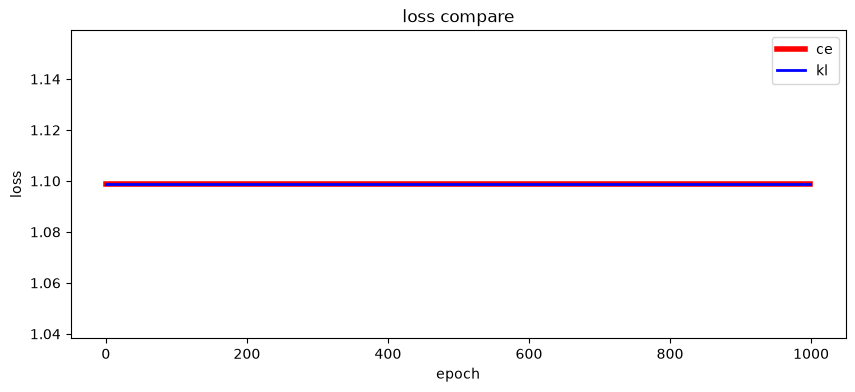

In [30]:
model1 = Logisticreg(lr=0.1,epoch=1000)
model2 = Logisticreg(lr=0.1,epoch=1000)

losses_ce = model1.fit(X_train, Y_train, loss='ce')
losses_kl = model2.fit(X_train, Y_train, loss='kl')

plt.figure(figsize=(10,4))
plt.plot(losses_ce,label="ce",color='red',linewidth=4)
plt.plot(losses_kl,label="kl",color='blue',linewidth=2)
plt.title("loss compare")
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()


              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00        22
     Class 1       0.94      1.00      0.97        16
     Class 2       1.00      0.95      0.98        22

    accuracy                           0.98        60
   macro avg       0.98      0.98      0.98        60
weighted avg       0.98      0.98      0.98        60

[[22  0  0]
 [ 0 16  0]
 [ 0  1 21]]


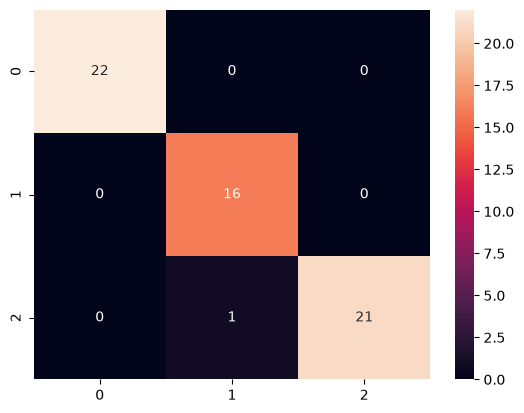

In [56]:
prediction = model1.predict(X_test)
trueclass = np.argmax(Y_test,axis=1)
print(classification_report(trueclass,prediction,target_names=['Class 0', 'Class 1', 'Class 2']))

cn = confusion_matrix(trueclass,prediction)
print(cn)
sns.heatmap(cn,annot=True)
plt.show()
